# AICE 분류 종합 연습 · 2026-11-21

구독 멤버십 해지 예측 · 가상 데이터 · 14문항

공식 기출이나 공식 채점 기준이 아닌 복습용 문제입니다. 두 파일을 같은 폴더에 두고 VS Code에서 풀이하세요. 처음에는 힌트 없이 풀고, 막힌 부분만 힌트를 확인하세요. 실행 결과를 저장한 ipynb를 제출하면 코드와 결과를 함께 검토합니다. 자동 채점 셀은 없습니다.

순서: 탐색 → 시각화 → 중복·이상치·결측치 처리 → 인코딩 → 분리 → 스케일링 → 머신러닝 → 딥러닝. 실무의 엄격한 검증에서는 전처리 통계도 훈련 데이터에서 학습하지만, 이번에는 문제 지시 순서를 따릅니다.

|컬럼|설명|
|---|---|
|customer_id|고객 식별번호|
|age|나이, 이 실습에서 100 초과는 이상치|
|region|거주 지역|
|plan_type|Basic/Standard/Premium 요금제|
|contact_channel|App/Phone/Web 이용 채널|
|tenure_months|가입 기간(개월)|
|monthly_fee|월 이용료(원)|
|weekly_usage_hours|주간 사용 시간|
|support_calls|문의 횟수|
|past_satisfaction|과거 만족도(1~5)|
|churn|해지 Yes / 유지 No|

필요 패키지: pandas, numpy, seaborn, matplotlib, scikit-learn, tensorflow. 성능 수치 자체에 목표값은 없습니다. 문제 조건과 평가 입력을 정확히 지키세요.


## 1. 라이브러리

pandas를 pd, numpy를 np, seaborn을 sns, matplotlib.pyplot을 plt로 불러오세요.

<details><summary>힌트 보기</summary>

import ... as ...

</details>


In [146]:
# 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2. 파일 확인

aice_membership_1121.csv를 data로 읽으세요. 처음 4행을 출력하고, 행·열 개수는 shape_answer, 컬럼별 결측치 수는 missing_answer에 저장하세요.

<details><summary>힌트 보기</summary>

셀 중간에서 출력하려면 print 또는 display를 사용하세요.

</details>


In [147]:
# 여기에 답안코드를 작성하고 실행하세요.
data = pd.read_csv("aice_membership_1121.csv")
data.head(4)

,customer_id,age,region,plan_type,contact_channel,tenure_months,monthly_fee,weekly_usage_hours,support_calls,past_satisfaction,churn
0,M0001,57.0,Busan,Standard,Web,38,39000,6.1,0,3.4,No
1,M0002,21.0,Yangsan,Standard,App,46,39000,1.0,6,2.4,Yes
2,M0003,63.0,Daegu,Standard,Phone,11,39000,5.8,4,4.8,Yes
3,M0004,27.0,Daegu,Premium,NaN,45,59000,17.9,6,3.3,No


In [148]:
shape_answer = data.shape
missing_answer = data.isna().sum()

## 3. 범주 분포

plan_type의 countplot을 그리고 제목을 Plan Count로 지정하세요. 요금제별 monthly_fee 평균을 fee_by_plan에 저장하세요.

<details><summary>힌트 보기</summary>

sns.countplot, groupby()[열].mean()

</details>


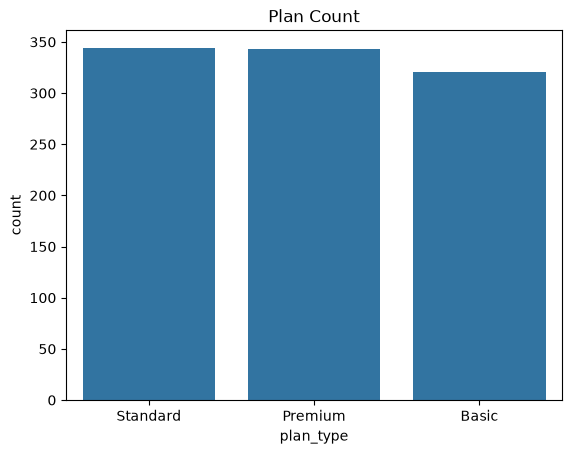

In [149]:
# 여기에 답안코드를 작성하고 실행하세요.
sns.countplot(data=data, x="plan_type")
plt.title("Plan Count")
plt.show()

In [150]:
fee_by_plan = data.groupby("plan_type")["monthly_fee"].mean()

## 4. 수치 분포

churn을 X축, past_satisfaction을 Y축으로 하는 boxplot을 그리세요.

<details><summary>힌트 보기</summary>

sns.boxplot(data=..., x=..., y=...)

</details>


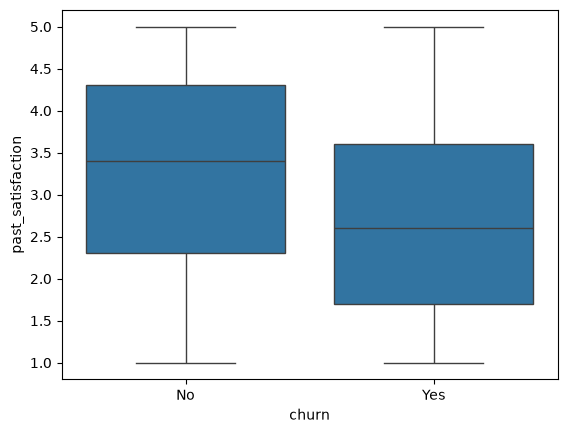

In [151]:
# 여기에 답안코드를 작성하고 실행하세요.
sns.boxplot(data=data, x="churn", y="past_satisfaction")
plt.show()

## 5. 중복·이상치

중복 행을 제거하고 age가 100 초과인 행을 제거하세요. age 결측 행은 유지하세요. customer_id를 삭제하고 인덱스를 초기화한 결과를 data_temp에 저장하세요.

<details><summary>힌트 보기</summary>

isna() | (age <= 100), reset_index(drop=True)

</details>


In [152]:
# 여기에 답안코드를 작성하고 실행하세요.
data = data.drop_duplicates()
data = data[(data["age"]<=100)|(data["age"].isna())]

data_temp = data.drop(columns=["customer_id"]).reset_index(drop=True)

## 6. 결측치

data_temp를 복사해 data_na를 만드세요. age와 weekly_usage_hours는 각 중앙값, past_satisfaction은 평균, contact_channel은 최빈값으로 채우세요. 전체 결측치 수를 출력하세요.

<details><summary>힌트 보기</summary>

최빈값 mode().iloc[0]을 fillna의 인자로 전달하세요. 원래 채널 값은 보존해야 합니다.

</details>


In [153]:
# 여기에 답안코드를 작성하고 실행하세요.
data_na = data_temp.copy()

med_cols = ["weekly_usage_hours", "age"]

for i in med_cols:
    data_na[i] = data_na[i].fillna(data_na[i].median())

data_na["past_satisfaction"] = data_na["past_satisfaction"].fillna(data["past_satisfaction"].mean())
data_na["contact_channel"] = data_na["contact_channel"].fillna(data_na["contact_channel"].mode().iloc[0])

In [154]:
print(data_na.isna().sum())

age                   0
region                0
plan_type             0
contact_channel       0
tenure_months         0
monthly_fee           0
weekly_usage_hours    0
support_calls         0
past_satisfaction     0
churn                 0
dtype: int64


## 7. 인코딩

data_na를 복사해 label_demo를 만드세요. 동일한 le를 반복 사용해 plan_type → contact_channel 순서로 라벨 인코딩하고, 각 fit 직후 classes_ 배열의 복사본을 class_maps[컬럼명]에 저장하세요. 별도로 data_na의 churn을 No:0, Yes:1로 바꾸세요. region, plan_type, contact_channel을 원핫 인코딩한 전체 데이터를 data_preset에 저장하세요(dtype=int, drop_first=False).

<details><summary>힌트 보기</summary>

le는 반복문 밖에서 생성. 저장 대상은 le.classes_.copy(). label_demo는 대응표 연습용이며 모델 입력은 data_na에서 만듭니다.

</details>


In [155]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
class_maps = {}
label_demo = data_na.copy()

loop_cols = ["plan_type", "contact_channel"]

for i in loop_cols:
    label_demo[i] = le.fit_transform(label_demo[i])
    class_maps[i] = le.classes_

data_na["churn"] = data_na["churn"].map({
    "No":0,
    "Yes":1
})

data_preset = pd.get_dummies(
    data_na,
    columns=["region", "plan_type","contact_channel"],
    dtype=int,
    drop_first=True
)

## 8. 데이터 분리

churn을 y, 나머지를 X로 두세요. test_size=0.2, random_state=42, stratify=y로 X_train, X_valid, y_train, y_valid를 만드세요.

<details><summary>힌트 보기</summary>

이번 실습은 결측치와 인코딩 처리 후 분리합니다.

</details>


In [156]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

X = data_preset.drop(columns=["churn"])
y = data_preset["churn"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 9. 스케일링

StandardScaler를 ss로 생성하세요. 훈련 기준으로 X_train_scaled와 X_valid_scaled를 만드세요.

<details><summary>힌트 보기</summary>

훈련 fit_transform, 검증 transform

</details>


In [157]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

X_train_scaled = ss.fit_transform(X_train)
X_valid_scaled = ss.transform(X_valid)

## 10. 머신러닝

LogisticRegression(max_iter=1000, random_state=42)을 lr로 생성해 스케일된 훈련 데이터로 학습하세요. RandomForestClassifier(n_estimators=50, random_state=42)에 max_depth=[3,5], min_samples_split=[2,5]를 GridSearchCV(cv=3, scoring="accuracy", n_jobs=-1)로 적용한 gs_rf를 만들고 스케일 전 훈련 데이터로 학습하세요.

<details><summary>힌트 보기</summary>

모델 생성 후 fit. RF에는 X_train을 넣습니다.

</details>


In [158]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import GridSearchCV

lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_scaled, y_train)

params = {
    "max_depth":[3,5],
    "min_samples_split":[2,5]
}

gs_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=50, random_state=42),
    params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

gs_rf.fit(X_train, y_train);

## 11. 변수 중요도

RF 최적 모델의 변수 중요도를 feature, importance 컬럼의 fi로 만드세요. 내림차순 상위 10개만 남기고 가로 막대그래프를 그리세요. 최고 변수명을 answer11에 저장하세요.

<details><summary>힌트 보기</summary>

gs_rf.best_estimator_.feature_importances_, X_train.columns. 최고 변수명은 fi에서 추출할 수 있습니다.

</details>


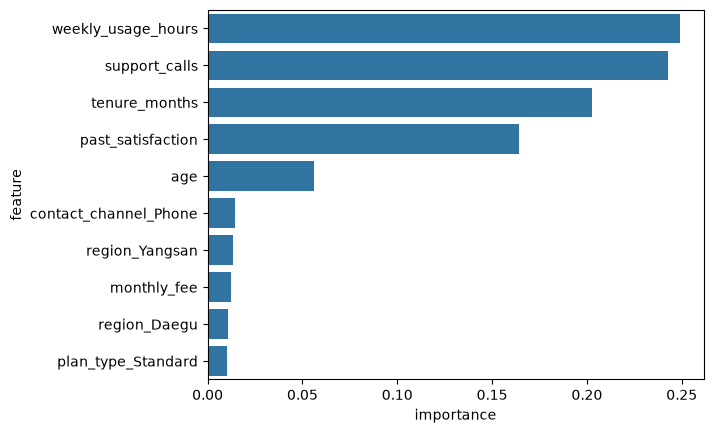

In [159]:
# 여기에 답안코드를 작성하고 실행하세요.
fi = pd.DataFrame({
    "feature":X_train.columns,
    "importance":gs_rf.best_estimator_.feature_importances_
}).sort_values("importance", ascending=False).head(10)

sns.barplot(data=fi, x="importance", y="feature")
plt.show()

answer = "weekly_usage_hours"

## 12. 분류 평가

lr의 검증 클래스 예측을 pred_lr, RF의 검증 클래스 예측을 pred_rf에 저장하세요. RF 클래스 순서를 출력하고 클래스 1의 예측 확률을 proba_rf에 저장하세요. RF 혼동행렬과 classification_report를 출력하고 ROC-AUC를 auc_rf에 저장하세요.

<details><summary>힌트 보기</summary>

lr에는 스케일된 검증 데이터, RF에는 스케일 전 데이터. ROC-AUC는 확률을 사용합니다.

</details>


In [160]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report

pred_lr = lr.predict(X_valid_scaled)
pred_rf = gs_rf.predict(X_valid)
proba_rf = gs_rf.predict_proba(X_valid)[:,1]

print(confusion_matrix(y_valid, pred_rf))
print(classification_report(y_valid, pred_rf))

auc_rf = roc_auc_score(y_valid, pred_rf)


[[109  11]
 [ 31  48]]
              precision    recall  f1-score   support

           0       0.78      0.91      0.84       120
           1       0.81      0.61      0.70        79

    accuracy                           0.79       199
   macro avg       0.80      0.76      0.77       199
weighted avg       0.79      0.79      0.78       199



## 13. 딥러닝·원핫 정답

model을 입력 특성 수 → Dense(32,relu) → Dropout(0.2) → Dense(16,relu) → Dense(2,sigmoid)로 구성하세요. adam, binary_crossentropy, accuracy로 컴파일하세요. to_categorical(num_classes=2)로 y_train_dl, y_valid_dl을 만드세요. estop은 val_loss, patience=5, restore_best_weights=True. checkpoint는 best_membership_1121.keras, val_loss, save_best_only=True. 스케일된 데이터와 원핫 정답으로 최대 30 epochs, batch_size=32, validation_data, 두 callbacks를 사용해 학습하고 history에 저장하세요.

<details><summary>힌트 보기</summary>

출력 2개와 정답 2칸을 맞추세요. fit에는 y_train_dl, validation_data에는 y_valid_dl. 파일명을 MODEL_FILE에 정의해도 됩니다. 이 출력 구성은 이번 문제의 지정 조건입니다.

</details>


In [161]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import to_categorical

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(2, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
y_train_dl = to_categorical(y_train, num_classes=2)
y_valid_dl = to_categorical(y_valid, num_classes=2)


In [162]:
estop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    filepath="best_membership_1121.keras",
    monitor="val_loss",
    save_best_only=True
)

history = model.fit(
    X_train_scaled,
    y_train_dl,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid, y_valid_dl),
    callbacks=[estop, checkpoint]
)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5962 - loss: 0.7163 - val_accuracy: 0.6030 - val_loss: 4216.5332
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6063 - loss: 0.6582 - val_accuracy: 0.6030 - val_loss: 4545.9731
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6226 - loss: 0.6265 - val_accuracy: 0.6030 - val_loss: 5226.9756
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6667 - loss: 0.5906 - val_accuracy: 0.6030 - val_loss: 5698.3730
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7006 - loss: 0.5682 - val_accuracy: 0.6030 - val_loss: 6124.3999
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7283 - loss: 0.5586 - val_accuracy: 0.6030 - val_loss: 6420.4097


## 14. 저장 모델·예측·그래프

저장한 모델을 best_model로 불러오세요. 검증 예측 전체를 dl_output에 저장하세요. 두 출력 중 큰 값의 열 번호를 dl_pred에, 클래스 1 출력값을 dl_proba에 저장하세요. 원래 정수 정답 y_valid로 혼동행렬과 ROC-AUC를 출력하세요. accuracy/val_accuracy를 한 그래프에 표시하세요(범례 acc/val_acc, 제목 Model Accuracy, 축 Epoch/Accuracy).

<details><summary>힌트 보기</summary>

이번에는 출력 2개이므로 dl_output.argmax(axis=1)로 클래스를 선택합니다. 클래스 1 점수는 dl_output[:,1]. sigmoid 출력 두 개의 합이 1일 필요는 없습니다. ravel이나 0.5 기준으로 두 출력을 한꺼번에 처리하지 마세요.

</details>


In [163]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import load_model

best_model = load_model("best_membership_1121.keras")

# 검증 예측 전체
dl_output = best_model.predict(X_valid_scaled)

# 최댓값의 위치
dl_pred = dl_output.argmax(axis=1)

dl_proba = dl_output[:, 1]

print(confusion_matrix(y_valid, dl_pred))
print(roc_auc_score(y_valid, dl_pred))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
[[117   3]
 [ 79   0]]
0.4875


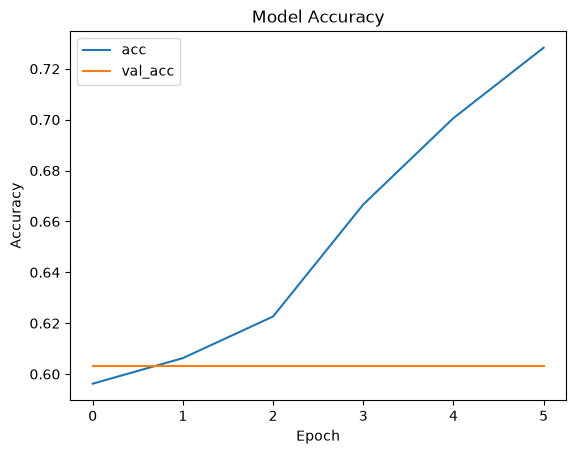

In [164]:
plt.plot(history.history["accuracy"], label="acc")
plt.plot(history.history["val_accuracy"], label="val_acc")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()